Dataset dimensions: (920, 17)
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
 16  target    920 non-null    int64  
dtypes: float64(5), int64(4), object(2), str(6)
memory usage: 420.8 KB
Total Memory: 0.41 MB
<class 'pandas.DataFrame'>
RangeIndex: 920

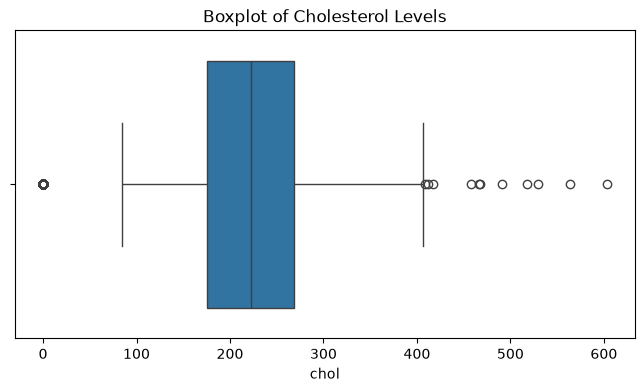

In [1]:
#step 1:data inspection and structure analysis
import pandas as pd
import numpy as np
df=pd.read_csv('heart_disease_dataset.csv')
#before doing anything:the target values are 0,1,2... the number of heart attacks so we need to convert them to binary values 0 and 1 so we will consider the values of 0 as no heart attack and the values of 1,2,3,4 as heart attack so we will convert them to 1
df['target'] = df["num"].apply(lambda x: 1 if x > 0 else 0)
df_clean=df.drop(columns=['num'])
#also there is one important thing we need to know is how to determine the correlation between the categorical features and the target variable so we will use chi-square(look code 2)
#1:check dimension of the dataset
print("Dataset dimensions:", df.shape)
#this check will tell us how many rows and columns are present in the dataset and if we are dealing with a large dataset or not
#if we are dealing with a large dataset we will have to use some techniques to optimize the memory usage of the dataset
#how to know the memory usage of the dataset?-->
df.info(memory_usage='deep')
#how to know the total memory usage of the dataset?-->
print(f"Total Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
#always we need 30-50% of the total memory to work with the dataset

#2:inspect data types and non-null counts of the dataset
df.info()
#this check will tell us the data types of each column and how many non-null values are present in each column
#the goal:ensure that the data types of each column are appropriate for the type of data they contain and to check for any missing values in the dataset
#so we need to know the percentege of missing values in each column of the dataset
missing_summary=pd.DataFrame({'Missing Count': df.isnull().sum(), 'Missing Percentage': df.isnull().sum()/len(df)*100})
print(missing_summary)
#ok now we need to handle missing values in the dataset
#so we have 4 ranges:<5% ,5-20%,20-50%,>50%
#i will start with <5% missing values
#here we have 3 strategies to handle missing values:
#u can see them in the documentation
#now i will use Simple Mean / Median Imputation 
#but how to know which one to use mean or median?
#we need to see if we have outliers in the dataset or not
#how to check for outliers in the dataset?-->
#using boxplot

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,4))
sns.boxplot(x=df['chol'])
plt.title('Boxplot of Cholesterol Levels')
plt.show()
#so the boxplot shows us that we have outliers in the dataset   
#first the 0 values are not valid for cholesterol levels so we need to replace them with NaN values
df['chol'] = pd.to_numeric(df['chol'], errors='coerce')  # Convert to numeric, coercing errors to NaN
df.loc[df['chol'] <= 0, 'chol'] = np.nan
#and the other values that are more than 300 are also outliers so we need to replace them with a cap value of 300
df['chol'] = df['chol'].clip(upper=300)
#now we can use median imputation to handle the missing values in the 'chol' column
chol_median = df['chol'].median()
df['chol']=df['chol'].fillna(chol_median)

#ok now i pass to the next column which is 'restecg' and it has  0.217% missing values so we will just drop the rows with missing values in this column 
df.dropna(subset=['restecg'], inplace=True)
#ok now  i pass to columns that have more than 5% missing values and less than 20% missing values which are 'trestbps','thalach','fbs','exang', and 'oldpeak' columns
#so here also we have 3 strategies to handle missing values:
#u can see them in the documentation
#each one depend on the context of the dataset and the type of data we have in each column
#now i will use Model-Based Imputation 
#and specially MICE
#what is MICE?-->
#MICE stands for Multiple Imputation by Chained Equations. It treats every column with missing values as a target variable and loops through them iteratively. It builds a regression or classification model for each column using all other columns, updating the missing cells in rounds until the values stabilize.
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
#but before that we need to check the data types of the columns that have missing values and convert them to numeric if they are not numeric
impute_cols = ['trestbps', 'thalch', 'fbs', 'exang', 'oldpeak']
for col in impute_cols:
    if df[col].dtype == 'object':
        df[col] = pd.to_numeric(df[col], errors='coerce')  
#we found that the 'fbs' and 'exang' columns are of object type(boolean) so we need to convert them to numeric type
#now i will create an instance of the IterativeImputer class
imputer = IterativeImputer(max_iter=10, random_state=42)
#now i will fit the imputer to the selected columns
df[impute_cols] = imputer.fit_transform(df[impute_cols])
#post-processing: after imputation, we need to round the values of 'fbs' and 'exang' columns to the nearest integer and convert them back to float type
df['fbs'] = df['fbs'].round().astype(float)
df['exang'] = df['exang'].round().astype(float)

#ok now i pass to the columns that have more than 20% missing values and less than 50% missing values which is 'slope' column
#so here also we have 2 strategies to handle missing values:
#u can see them in the documentation
#and bcz the slope is a categorical column so we will use the most frequent technique for categorical features
#is called Explicit "Missing" Category 
#what is Explicit "Missing" Category?-->
#replace missing string/category values with a dedicated label like 'Missing'
df['slope'] = df['slope'].fillna('Missing')
#now i pass to the columns that have more than 50% missing values which is 'ca' and 'thal' columns
#i will start first with 'thal' which is a categorical column represents a test so in easy way the null comlumns they are patients that didn't do the test so we will replace the missing values with a dedicated label like 'Not Tested'
df['thal'] = df['thal'].fillna('Not Tested')
#for the ca also as it's a categorical column represents a test so in easy way the null comlumns they are patients that didn't do the test so we will replace the missing values with a dedicated label like -1
df['ca'] = df['ca'].fillna(-1)


In [2]:
from scipy.stats import chi2_contingency
import pandas as pd
cotingency_table = pd.crosstab(df['ca'], df['target'])
chi2, p, dof, expected = chi2_contingency(cotingency_table)
print(f"Chi-square statistic: {chi2}, p-value: {p}")

Chi-square statistic: 87.68694589960924, p-value: 4.080570354192763e-18


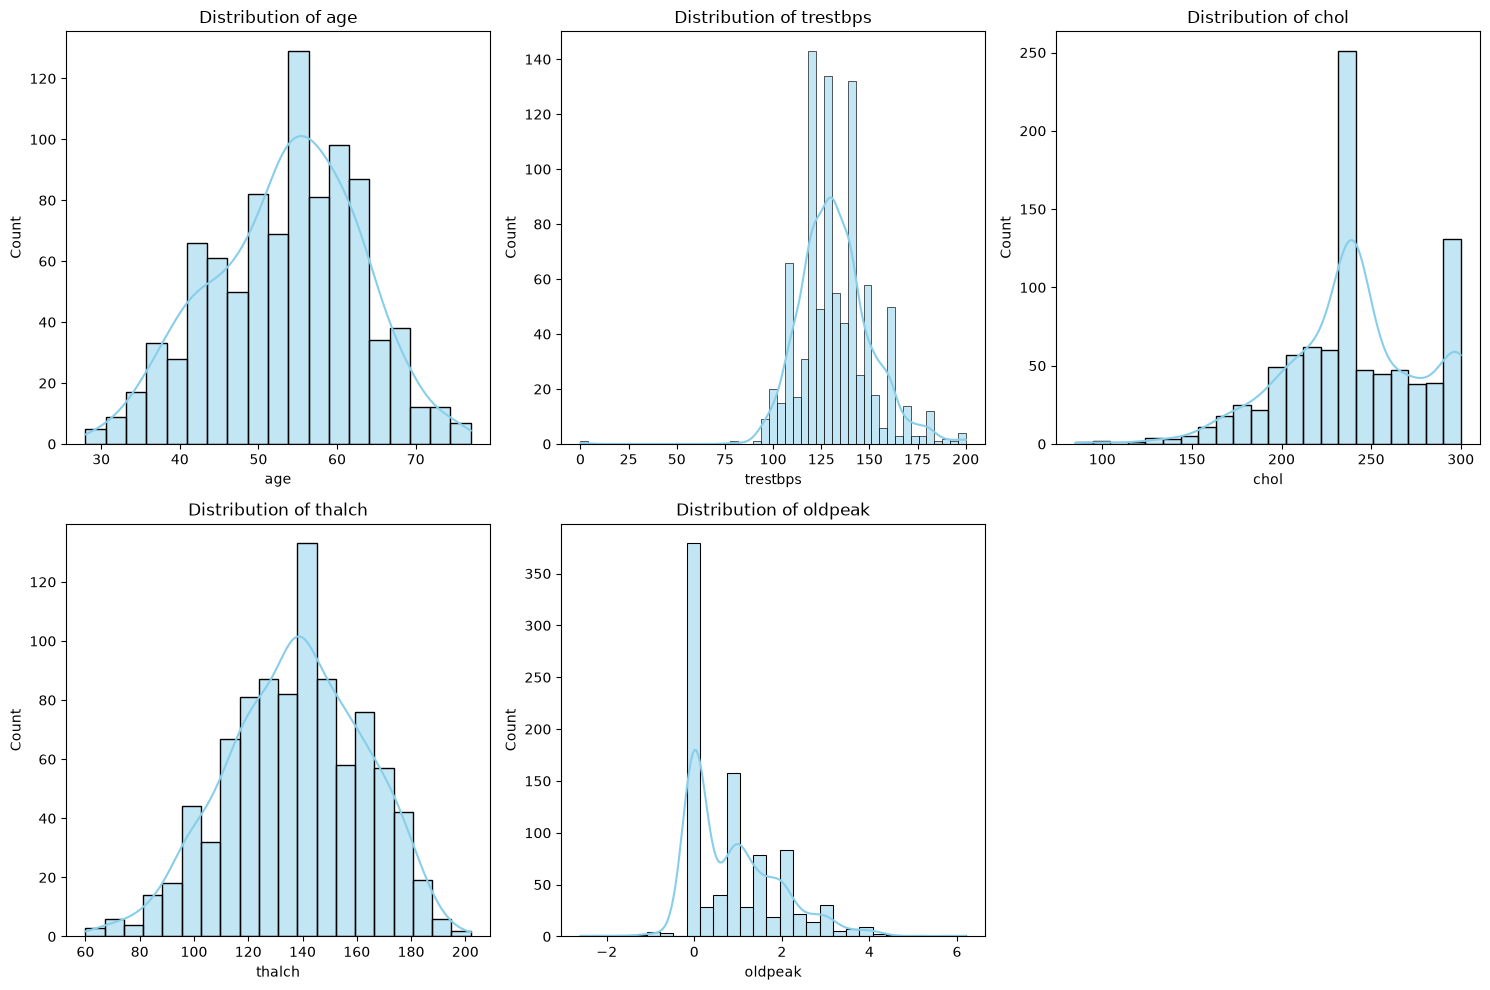

Skewness of numerical features:
age        -0.193710
trestbps    0.196644
chol       -0.351275
thalch     -0.208429
oldpeak     1.063805
dtype: float64


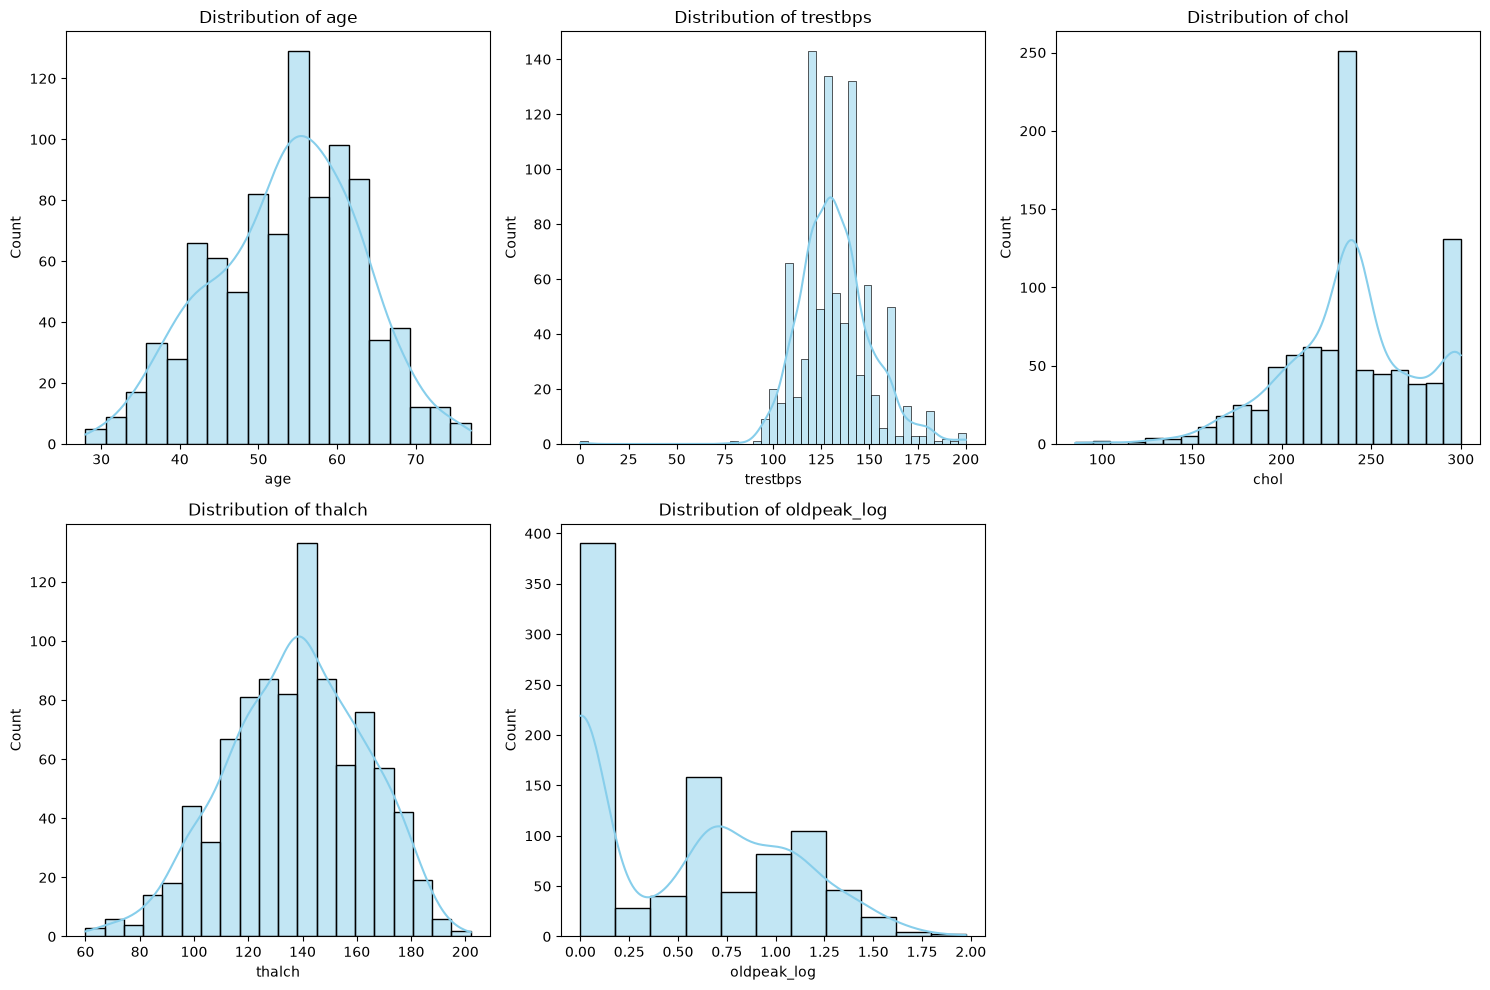

Skewness of numerical features:
age           -0.193710
trestbps       0.196644
chol          -0.351275
thalch        -0.208429
oldpeak_log    0.409337
dtype: float64
Class distribution of categorical features:

Feature:sex
        Counts  Percentage
sex                       
Male       724       78.87
Female     194       21.13

Feature:cp
                 Counts  Percentage
cp                                 
asymptomatic        495       53.92
non-anginal         204       22.22
atypical angina     174       18.95
typical angina       45        4.90

Feature:fbs
     Counts  Percentage
fbs                    
0.0     780       84.97
1.0     138       15.03

Feature:restecg
                  Counts  Percentage
restecg                             
normal               551       60.02
lv hypertrophy       188       20.48
st-t abnormality     179       19.50

Feature:exang
       Counts  Percentage
exang                    
0.0       580       63.18
1.0       338       36.82

Feature:s

In [ ]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Univariate Analysis
#here we will analyze each feature individually
#for numerical features we will inspect variables to check if they follow a normal distribution or are heavily skewed
#what does heavily skewed mean?-->
#When a variable is heavily skewed, its data values are not evenly distributed around the mean. Instead, most data points cluster on one side

num_cols=['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
plt.figure(figsize=(15, 10))
for i,col in enumerate(num_cols,1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True,color='skyblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

print("Skewness of numerical features:")
print(df[num_cols].skew())
#if the skewness is greater than 1 or less than -1, the feature is highly skewed. If the skewness is between -1 and -0.5 or between 0.5 and 1, the feature is moderately skewed. If the skewness is between -0.5 and 0.5, the feature is approximately symmetric.
#why we use skewness?-->
#first it has influence on the model algorithms and their performance
#Linear models (Logistic Regression, Linear SVM, Neural Networks) perform poorly on heavily skewed features. If skewness is high, apply a Log Transformation
#Tree-Based Models: If you use Tree algorithms (Random Forest, XGBoost), skewness doesn't hurt them
#but what's log transformation?-->
#Log transformation is a mathematical operation that applies the logarithm function to each value in a dataset
#x'=log(x)
#example log(10)=2.30
#also the skewness help in deciding which feature scaling technique to use
#StandardScaler (Z-Score Standardization): Best used when features are roughly normally distributed (bell-shaped)
#RobustScaler: Best used when features are heavily skewed or contain extreme high values
#MinMaxScaler: Rescales values between 0 and 1, best used when features have bounded ranges and minimal skewness.
#so now i will log transform the 'oldpeak' 

import numpy as np
df['oldpeak'] = df['oldpeak'].clip(lower=0)
df['oldpeak_log'] = np.log1p(df['oldpeak'])
df=df.drop(columns=['oldpeak'])
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

print("Skewness of numerical features:")
print(df[num_cols].skew())

#now we pass to the categorical features
#here we don't measure skewness but we look for Class Imbalance or we can say Dominant Categories
#so a feature is considered heavily imbalanced if one category represents more than 90% of the total observations
#let's first check the categorical features in the dataset
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
print("Class distribution of categorical features:")
for col in cat_cols:
    print(f"\nFeature:{col}")
    percentage=df[col].value_counts(normalize=True) * 100
    counts = df[col].value_counts()
    summary_df = pd.DataFrame({'Counts': counts, 'Percentage': percentage.round(2)})
    print(summary_df)
#interpretation: if we have a feature that has a category that represents 85%-90% of the total observations, we can say that this feature is heavily imbalanced 
#the actionable decision:
#<85%: No action needed
#85%-90%:here we need to monitor feature importance during model evaluation(we will see later on)
#>90%: drop column
#in this dataset we don't have any categorical feature that is heavily imbalanced so we don't need to take any action

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23392\1235344331.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23392\1235344331.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23392\1235344331.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4

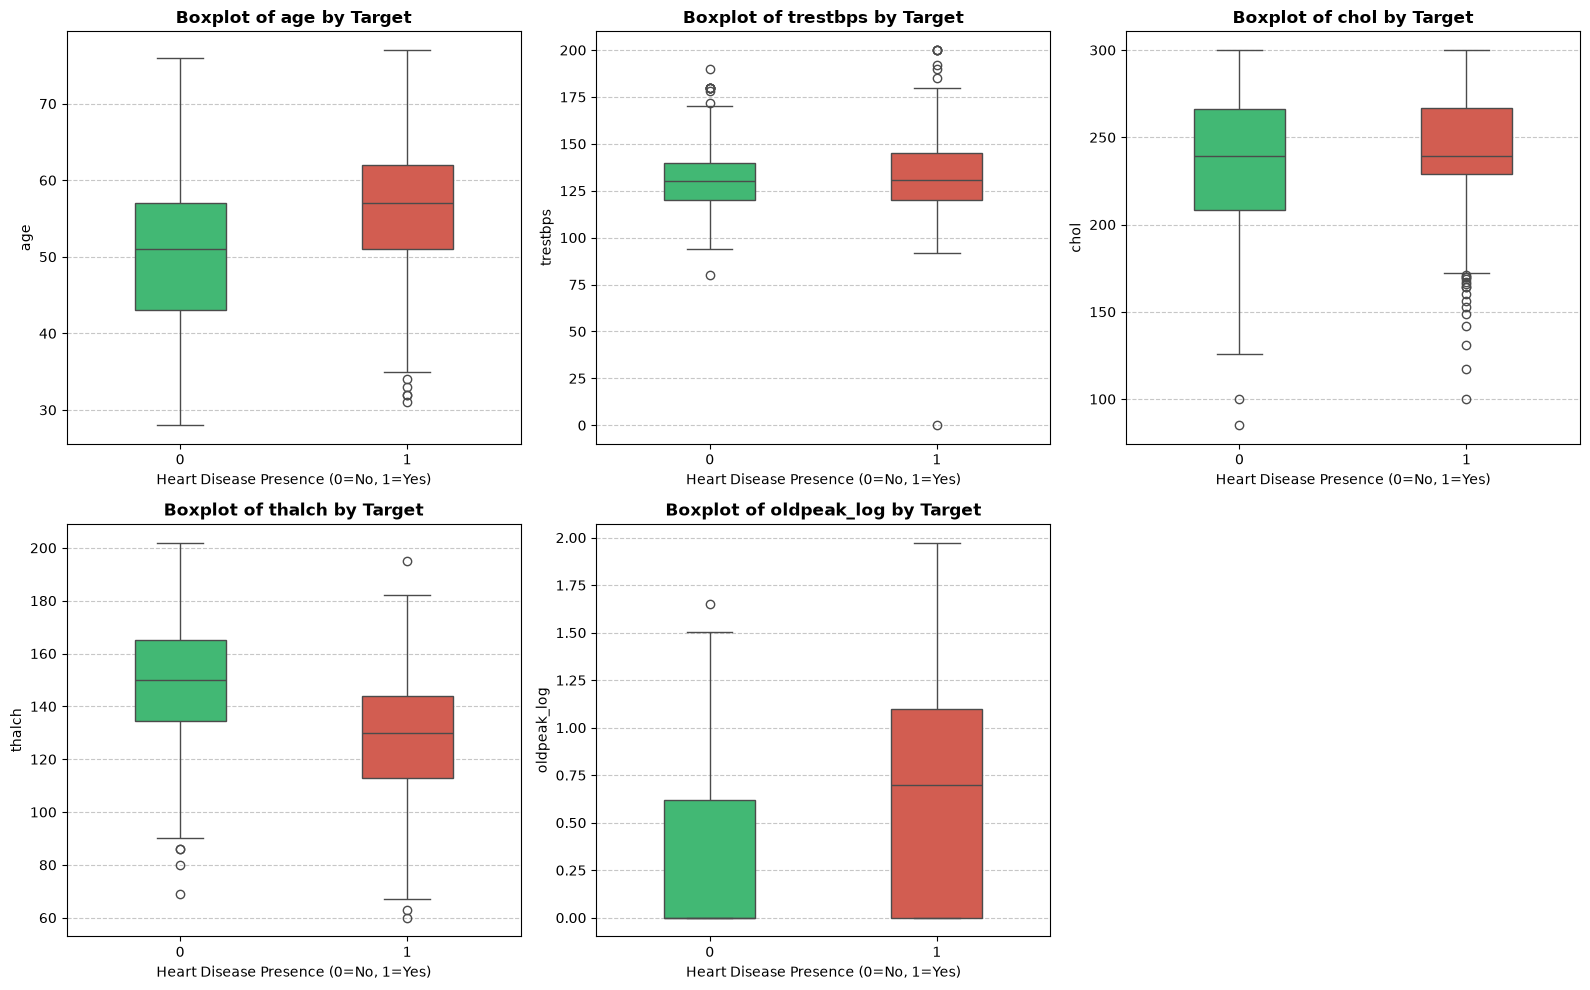

In [ ]:
#Step 2:Exploratory Data Analysis (EDA) and Feature Engineering
#Phase 1: Bivariate Analysis
#so here we will analyze the relationship between each feature and the target variable
#we focus on evaluating how each independent feature interacts with the target variable
#objectives:
#1: Identify features that have a strong relationship with the target variable(or with other features), which can be useful
#2: Detect redundant features that may not contribute much to the model's predictive power so it's better if we drop them or de-prioritize them
#3:Guide engineering decisions:Reveal linear or non-linear relationships that inform feature transformations or algorithm selection
#we have 3 types of bivariate analysis: 
#1:Contingous vs Binary(numerical vs target)
#2:Categorical vs Binary(categorical vs target)
#3:Continous vs Continous(Feature vs Feature)
#let's start with the first type which is Contingous vs Binary(numerical vs target)
#goal:Compare the distributions of numerical features across the two classes of the target variable
#step1:visual inspection: we will use boxplots and overlaid distribution
#we use boxplots to compare medians,interquartile ranges(IQR), and potential outliers between the two classes
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak_log']
plt.figure(figsize=(16,10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='target', y=col, data=df, palette=['#2ecc71', '#e74c3c'],width=0.4)
    plt.title(f'Boxplot of {col} by Target', fontsize=12, fontweight='bold')
    plt.xlabel('Heart Disease Presence (0=No, 1=Yes)')
    plt.ylabel(col)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#this boxplot shows us the distribution of each numerical feature across the two classes of the target variable
#and determine the seperation degree between the two classes for each feature
#for our dataset we can see that the 'thalch' and 'oldpeak_log' features show a more pronounced separation between the two classes
#and the others show less distinct separation.